# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Evina Fitriyani | 5054251013 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import sys
print(sys.executable)

c:\DL\.venv\Scripts\python.exe


In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

tf.keras.utils.set_random_seed(42)
print(tf.__version__)

2.21.0


In [4]:
import os

print("Folder kerja:", os.getcwd())
print("File dalam folder:")
print(os.listdir())

Folder kerja: c:\Users\ACER\OneDrive\Videos\Screen Recordings\Project\Tugas ML\8. 5054251013_Deep Learning
File dalam folder:
['.venv', '1_DL_5054251013.ipynb', '2_DL_5054251013.ipynb', 'fashion-mnist_test-selected-columns.csv']


In [5]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('Churn_Modelling.csv')
display(df.head())
print('Ukuran data:', df.shape)
print()
df.info()
print()
display(df.describe())
print('Jumlah missing value:', df.isnull().sum().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Ukuran data: (10000, 14)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB



,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Jumlah missing value: 0
Jumlah baris duplikat: 0


Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


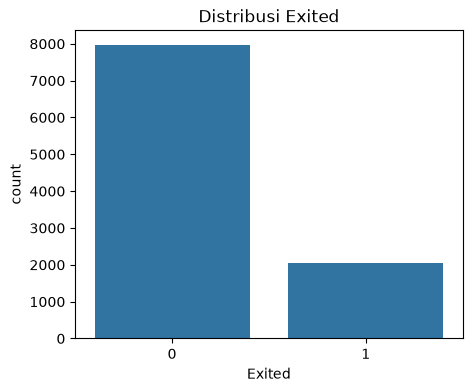

In [6]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

print(df['Exited'].value_counts())
print(df['Exited'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(x='Exited', data=df)
plt.title('Distribusi Exited')
plt.show()

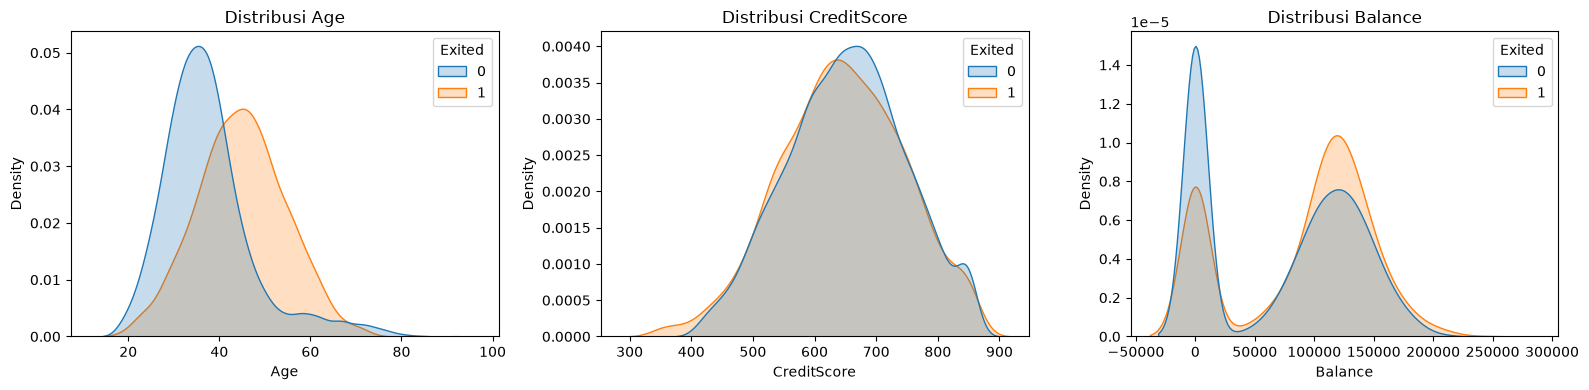

In [7]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(['Age', 'CreditScore', 'Balance']):
    sns.kdeplot(data=df, x=col, hue='Exited', common_norm=False, fill=True, ax=ax[i])
    ax[i].set_title('Distribusi ' + col)
plt.tight_layout()
plt.show()

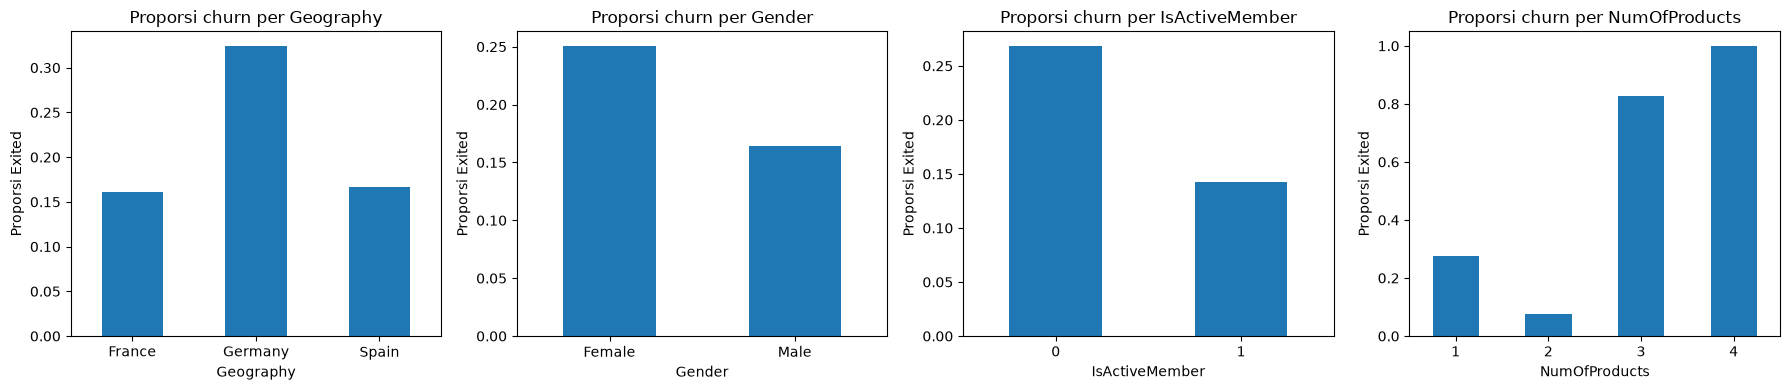

In [8]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']):
    churn_rate = df.groupby(col)['Exited'].mean()
    churn_rate.plot(kind='bar', ax=ax[i])
    ax[i].set_title('Proporsi churn per ' + col)
    ax[i].set_ylabel('Proporsi Exited')
    ax[i].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

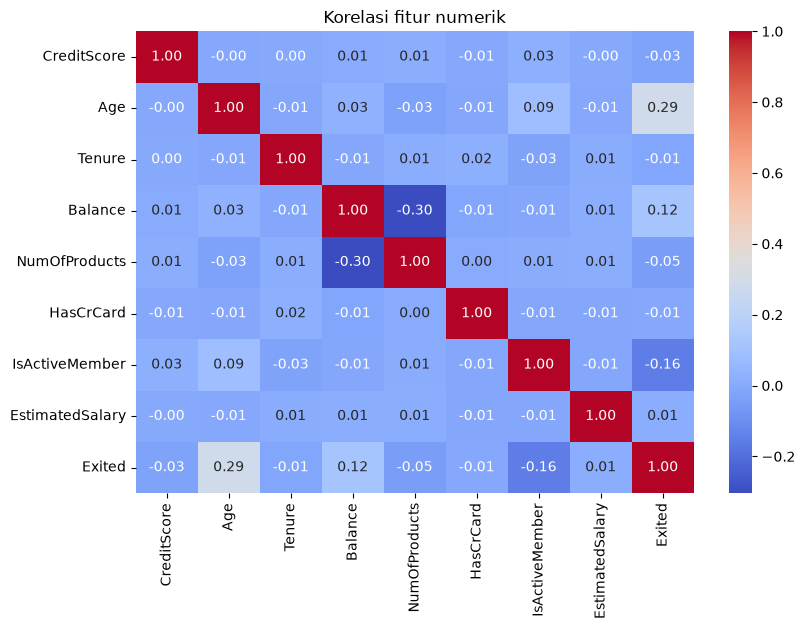

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
Exited,,,,,,,,
0,651.85,37.41,5.03,72745.30,1.54,0.71,0.55,99738.39
1,645.35,44.84,4.93,91108.54,1.48,0.70,0.36,101465.68


In [9]:
# korelasi antar fitur numerik dan target
num_df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Geography', 'Gender'])
plt.figure(figsize=(9, 6))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi fitur numerik')
plt.show()

# rata-rata fitur untuk tiap kelas
num_df.groupby('Exited').mean().round(2)

Pengamatan EDA
- Data termasuk imbalanced, karena dari 10.000 nasabah, 7.963 (79,6%) tidak churn dan 2.037 (20,4%) churn. Tidak ada missing value maupun data duplikat.
- Nasabah yang churn rata-rata lebih tua (44,8 tahun) dan punya saldo lebih besar dibandingkan yang tidak churn. Usia juga menjadi fitur yang paling berhubungan dengan churn (korelasi 0,285). Sekitar 36% nasabah memiliki saldo 0.
- Churn paling tinggi berasal dari Germany (32,4%), nasabah perempuan (25,1%), dan nasabah yang tidak aktif (26,9%).
- Jumlah produk juga berpengaruh. Nasabah dengan 1 produk memiliki churn 27,7%, 2 produk 7,6%, 3 produk 82,7%, dan 4 produk 100% (60 nasabah).
- Sementara itu, CreditScore, Tenure, EstimatedSalary, dan HasCrCard tidak menunjukkan perbedaan yang terlalu besar antara nasabah yang churn dan tidak churn.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [10]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

df_model = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
# RowNumber cuma nomor urut baris, CustomerId cuma ID unik nasabah, dan Surname nama belakang (hampir unik)
# ketiganya tidak punya hubungan dengan keputusan churn dan kalau dipakai malah bisa bikin model menghafal
print(df_model.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [11]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop('Exited', axis=1)
y = df_model['Exited']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print('Train:', X_train.shape, '| proporsi churn:', round(y_train.mean(), 4))
print('Val  :', X_val.shape, '| proporsi churn:', round(y_val.mean(), 4))
print('Test :', X_test.shape, '| proporsi churn:', round(y_test.mean(), 4))

Train: (7000, 10) | proporsi churn: 0.2037
Val  : (1500, 10) | proporsi churn: 0.204
Test : (1500, 10) | proporsi churn: 0.2033


In [12]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Gender jadi 0/1
for d in [X_train, X_val, X_test]:
    d['Gender'] = d['Gender'].map({'Female': 0, 'Male': 1})

num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('geo', OneHotEncoder(sparse_output=False), ['Geography'])
], remainder='passthrough')

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

print(preprocessor.get_feature_names_out())
print('Jumlah fitur:', X_train.shape[1])

['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__EstimatedSalary' 'geo__Geography_France'
 'geo__Geography_Germany' 'geo__Geography_Spain' 'remainder__Gender'
 'remainder__HasCrCard' 'remainder__IsActiveMember']
Jumlah fitur: 12


In [13]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")

X_train = np.asarray(X_train, dtype='float32')
X_val = np.asarray(X_val, dtype='float32')
X_test = np.asarray(X_test, dtype='float32')
y_train = np.asarray(y_train, dtype='float32')
y_val = np.asarray(y_val, dtype='float32')
y_test = np.asarray(y_test, dtype='float32')

print(X_train.shape, X_val.shape, X_test.shape)
print(X_train.dtype, y_train.dtype)

(7000, 12) (1500, 12) (1500, 12)
float32 float32


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [14]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
print('Akurasi test Logistic Regression:', round(accuracy_score(y_test, y_pred_lr), 4))

Akurasi test Logistic Regression: 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [15]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

tf.keras.utils.set_random_seed(42)

model_1 = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.

model_1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                loss='binary_crossentropy',
                metrics=['accuracy'])

history_1 = model_1.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=50, batch_size=32, verbose=0)

print('Epoch terakhir -> loss:', round(history_1.history['loss'][-1], 4),
      '| val_loss:', round(history_1.history['val_loss'][-1], 4))
print('Epoch terakhir -> acc:', round(history_1.history['accuracy'][-1], 4),
      '| val_acc:', round(history_1.history['val_accuracy'][-1], 4))

Epoch terakhir -> loss: 0.3382 | val_loss: 0.3261
Epoch terakhir -> acc: 0.8591 | val_acc: 0.8667


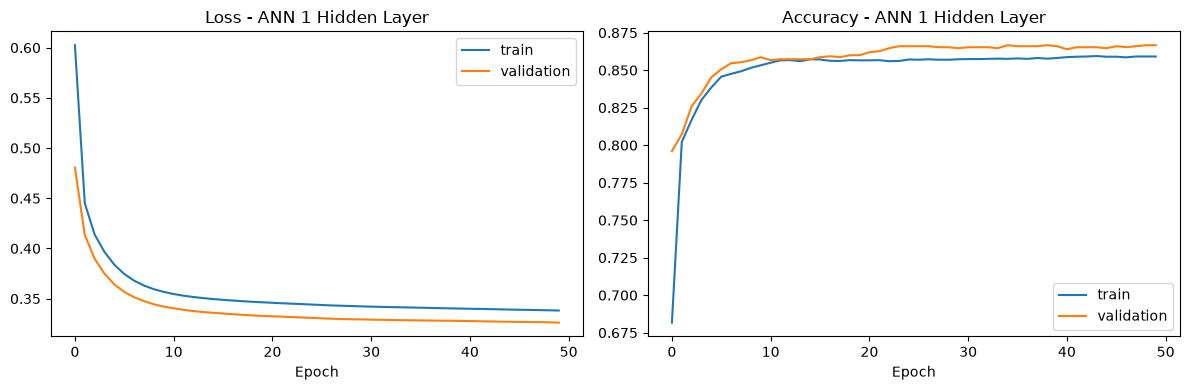

In [17]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].

def plot_history(history, judul):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['loss'], label='train')
    ax[0].plot(history.history['val_loss'], label='validation')
    ax[0].set_title('Loss - ' + judul)
    ax[0].set_xlabel('Epoch')
    ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='train')
    ax[1].plot(history.history['val_accuracy'], label='validation')
    ax[1].set_title('Accuracy - ' + judul)
    ax[1].set_xlabel('Epoch')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_1, 'ANN 1 Hidden Layer')

In [18]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.

y_prob_ann1 = model_1.predict(X_test, verbose=0).ravel()
y_pred_ann1 = (y_prob_ann1 >= 0.5).astype(int)
print('Akurasi test ANN 1 hidden layer:', round(accuracy_score(y_test, y_pred_ann1), 4))

Akurasi test ANN 1 hidden layer: 0.8687


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [19]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.

tf.keras.utils.set_random_seed(42)

model_2 = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch terakhir -> loss: 0.3285 | val_loss: 0.329
Epoch terakhir -> acc: 0.8624 | val_acc: 0.8647


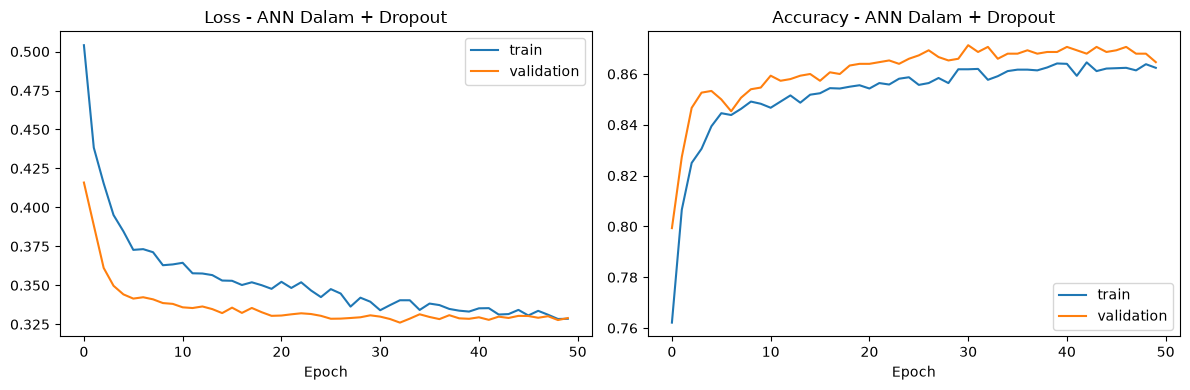

In [20]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

model_2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                loss='binary_crossentropy',
                metrics=['accuracy'])

history_2 = model_2.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=50, batch_size=32, verbose=0)

print('Epoch terakhir -> loss:', round(history_2.history['loss'][-1], 4),
      '| val_loss:', round(history_2.history['val_loss'][-1], 4))
print('Epoch terakhir -> acc:', round(history_2.history['accuracy'][-1], 4),
      '| val_acc:', round(history_2.history['val_accuracy'][-1], 4))

plot_history(history_2, 'ANN Dalam + Dropout')

In [21]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_prob_ann2 = model_2.predict(X_test, verbose=0).ravel()
y_pred_ann2 = (y_prob_ann2 >= 0.5).astype(int)
print('Akurasi test ANN dalam + Dropout:', round(accuracy_score(y_test, y_pred_ann2), 4))

Akurasi test ANN dalam + Dropout: 0.8667


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [22]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.

# pakai arsitektur 3.3 karena val accuracy-nya sedikit lebih tinggi dari 3.2 (0.8687 vs 0.8667), selisihnya tipis
tf.keras.utils.set_random_seed(42)

# arsitektur sama dengan model 3.3, dibuat ulang supaya bobot mulai dari awal
model_3 = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print('Class weight:', class_weight)

model_3.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                loss='binary_crossentropy',
                metrics=['accuracy'])

history_3 = model_3.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=50, batch_size=32,
                        class_weight=class_weight, verbose=0)

Class weight: {0: 0.6279153211338356, 1: 2.4544179523141656}


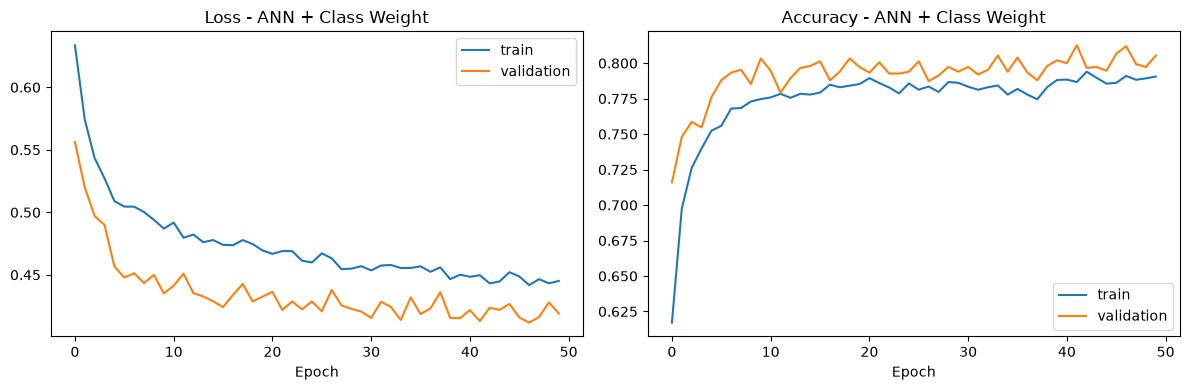

Akurasi test ANN + class weight: 0.8013


In [23]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history_3, 'ANN + Class Weight')

y_prob_ann3 = model_3.predict(X_test, verbose=0).ravel()
y_pred_ann3 = (y_prob_ann3 >= 0.5).astype(int)
print('Akurasi test ANN + class weight:', round(accuracy_score(y_test, y_pred_ann3), 4))

# 4. Evaluasi Model

In [24]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

hasil = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'ANN 1 Hidden Layer': (y_pred_ann1, y_prob_ann1),
    'ANN Dalam + Dropout': (y_pred_ann2, y_prob_ann2),
    'ANN + Class Weight': (y_pred_ann3, y_prob_ann3)
}

baris = []
for nama, (yp, pr) in hasil.items():
    baris.append([nama,
                  accuracy_score(y_test, yp),
                  precision_score(y_test, yp),
                  recall_score(y_test, yp),
                  f1_score(y_test, yp),
                  roc_auc_score(y_test, pr)])

tabel_hasil = pd.DataFrame(baris, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC'])
tabel_hasil.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
1,ANN 1 Hidden Layer,0.8687,0.8068,0.4656,0.5904,0.8657
2,ANN Dalam + Dropout,0.8667,0.7807,0.4787,0.5935,0.8635
3,ANN + Class Weight,0.8013,0.5078,0.7443,0.6037,0.8616


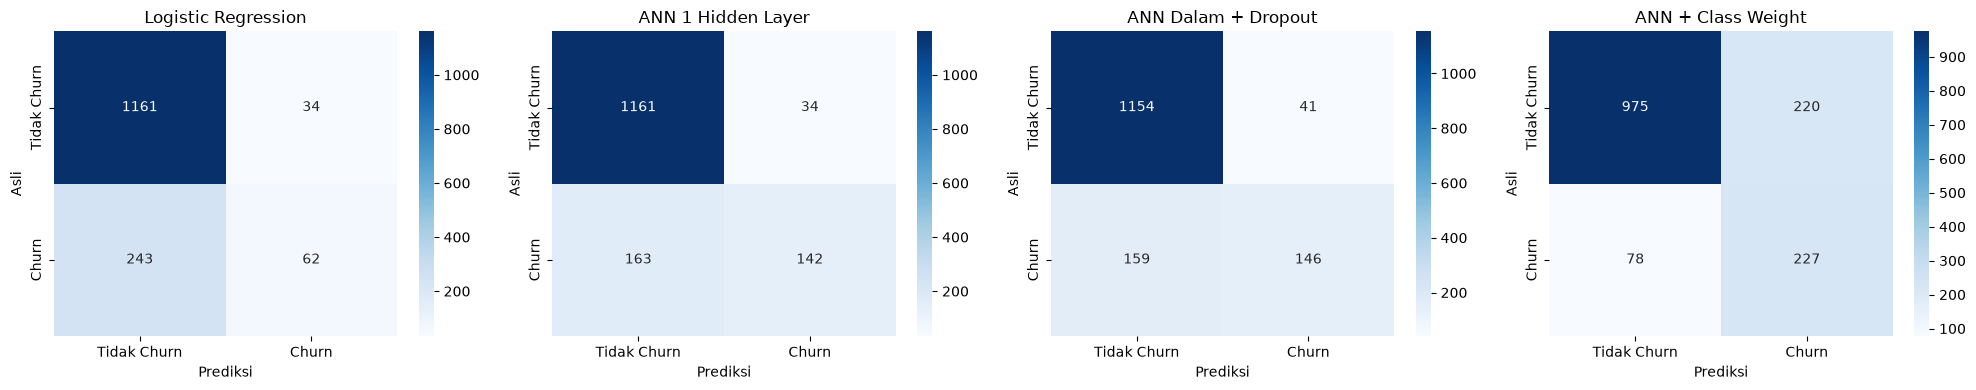

In [25]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i, (nama, (yp, pr)) in enumerate(hasil.items()):
    cm = confusion_matrix(y_test, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[i],
                xticklabels=['Tidak Churn', 'Churn'], yticklabels=['Tidak Churn', 'Churn'])
    ax[i].set_title(nama)
    ax[i].set_xlabel('Prediksi')
    ax[i].set_ylabel('Asli')
plt.tight_layout()
plt.show()

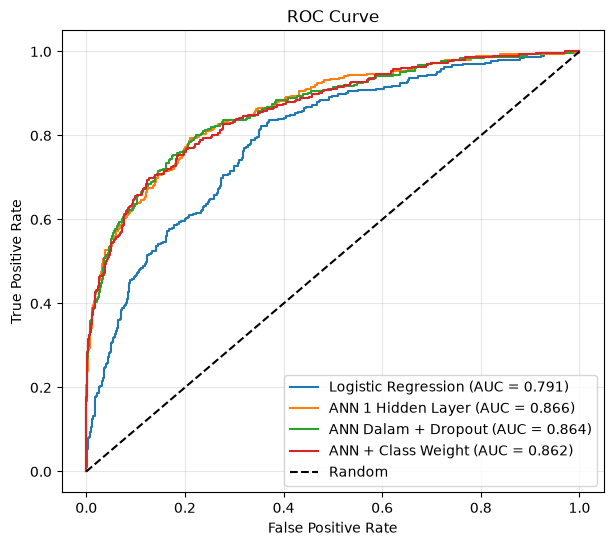

In [26]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for nama, (yp, pr) in hasil.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=nama + ' (AUC = ' + str(round(roc_auc_score(y_test, pr), 3)) + ')')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5. Analisis

#### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Jawaban:**

Perbandingan model. Logistic Regression mendapatkan accuracy 0.8153, tetapi recall churn-nya hanya 0.2033. Artinya, model ini masih banyak gagal mendeteksi nasabah yang benar-benar churn. Ketiga model ANN punya hasil yang lebih baik, terutama dari nilai AUC yang naik dari 0.7913 menjadi sekitar 0.86–0.87. Kemungkinan karena pola pada data churn tidak semuanya linear, sehingga ANN bisa menangkap pola yang kurang terlihat pada Logistic Regression.

ANN 1 hidden layer (3.2). Model ini mendapatkan hasil terbaik dari sisi accuracy (0.8687), F1 (0.5904), dan AUC (0.8657). Learning curve-nya juga cukup stabil. Loss training dan validation sama-sama turun, lalu mulai mendatar sekitar epoch 15–20. Jarak keduanya juga dekat, jadi belum terlihat tanda overfitting. Menurutku, model ini sudah cukup baik, walaupun recall churn-nya masih 0.4656.

ANN lebih dalam + Dropout (3.3). Hasilnya sedikit lebih rendah dibandingkan model sebelumnya, dengan accuracy 0.8627, F1 0.5744, dan AUC 0.8627. Padahal jumlah parameternya jauh lebih banyak. Kurva loss terlihat lebih naik turun karena adanya Dropout. Hal ini masih wajar karena Dropout hanya aktif saat training. Dari kurvanya juga belum terlihat overfitting yang berarti. Jadi, penambahan layer dan Dropout ternyata belum memberikan peningkatan hasil pada eksperimen ini.

Class weight (3.4). Pada model ini, recall churn meningkat cukup besar dari 0.4557 menjadi 0.7410. Artinya, lebih banyak nasabah yang benar-benar churn berhasil terdeteksi. Namun, precision turun dari 0.7765 menjadi 0.4860 karena model jadi lebih sering memprediksi nasabah sebagai churn. Accuracy juga turun menjadi 0.7880, sedangkan F1 sedikit naik menjadi 0.5870. AUC hampir tidak berubah. Learning curve-nya memang lebih naik turun, tetapi belum menunjukkan tanda overfitting yang jelas.


# 6. Kesimpulan dan Saran

#### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**
Semua model ANN mendapatkan hasil lebih baik dibandingkan Logistic Regression. ANN 1 hidden layer menjadi model terbaik dengan accuracy 0.8687, F1 0.5904, dan AUC 0.8657. Penambahan layer dan Dropout belum meningkatkan performa model.

Dataset juga memiliki jumlah data churn yang tidak seimbang (20,4%). Penggunaan class weight berhasil meningkatkan recall menjadi 0.7410, tetapi precision dan accuracy menurun. Jadi, pemilihan model perlu disesuaikan dengan tujuan, apakah ingin mendapatkan prediksi yang lebih akurat atau mendeteksi lebih banyak nasabah yang berpotensi churn.

**Saran**
- Mengatur threshold prediksi menggunakan Precision-Recall Curve untuk mencari keseimbangan antara precision dan recall.
- Menambahkan fitur baru, seperti penanda saldo 0 atau kombinasi Age dan IsActiveMember.
- Menggunakan EarlyStopping dan mencoba beberapa seed atau cross-validation agar hasil eksperimen lebih konsisten.
- Membandingkan hasil ANN dengan model lain seperti Random Forest atau XGBoost.